# Fake News Detection using Natural Language Processing

**Name:** Pavithra Deepu E  
**Register number:** ASI23CA049  
**Guide:** Dr. Sarika S  
**Academic year:** 2026

## Project idea
In this project, I classify short English political
statements into two groups: **REAL** and **FAKE**. Then compare Naive Bayes and
Logistic Regression using the LIAR dataset. The model learns patterns in the
words. It does not search the internet to check whether a statement is true.

The notebook includes the code, explanations, model training, results, graphs,
simple tests, and an example prediction.

GitHub folder: https://github.com/pavithradeepue/ASIET/S7/NLP

## How to run this notebook

1. Upload this `.ipynb` file to Google Colab.
2. Choose **Runtime → Run all**. A CPU runtime is enough.
3. Wait for all cells to finish. The notebook downloads the dataset when needed.
4. Change the example statement in Step 15 to try your own prediction.

For an offline rerun, set the
optional archive path in Step 3 to a copy of the original dataset ZIP.

### Project steps
Setup → load data → clean text → TF-IDF → train models → select a model →
test it → show graphs → save files → try a prediction.

## Step 1 Check the required libraries

A **library** is a collection of ready-made tools. This cell installs a library
only if it is missing.


In [1]:
import importlib.util
import subprocess
import sys

required_libraries = {
    "numpy": "numpy",
    "pandas": "pandas",
    "sklearn": "scikit-learn",
    "matplotlib": "matplotlib",
    "joblib": "joblib"
}

missing_libraries = []

for module_name, package_name in required_libraries.items():
    if importlib.util.find_spec(module_name) is None:
        missing_libraries.append(package_name)

if missing_libraries:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "--quiet",
        *missing_libraries
    ])

print("All required libraries are available.")
print("Python version:", sys.version.split()[0])

All required libraries are available.
Python version: 3.13.16


## Step 2 Import the tools

`pandas` reads and organizes the data. `scikit-learn` provides the models and
scores. `matplotlib` draws the graphs. `joblib` saves the trained model.
The other imports help with text cleaning, downloads, ZIP files, and saving results.

**Output:** the software versions used for this run.

In [2]:
import hashlib
import html
import io
import json
import platform
import re
import shutil
import unicodedata
import urllib.error
import urllib.request
import zipfile
from pathlib import Path

import joblib
import matplotlib
matplotlib.use("Agg")  # Save graphs as images and display them in the notebook.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

from IPython.display import Image, FileLink, Markdown, display
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score,
    roc_curve
)
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

print("scikit-learn:", sklearn.__version__)
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)

scikit-learn: 1.6.1
pandas: 2.2.3
NumPy: 2.1.3
Matplotlib: 3.10.0


## Step 3 Set the labels and file locations

The original LIAR dataset has six levels of truthfulness. This project uses a
simplified binary task:

| Original label | Project label |
|---|---|
| true, mostly-true | REAL = 0 |
| false, barely-true, pants-fire | FAKE = 1 |
| half-true | Excluded because it is ambiguous |

These names simplify the original labels. **REAL does not mean every detail is
correct, and FAKE does not mean the entire statement is invented/fake.**

The seed is a fixed number used to make supported random operations repeatable.
The `results` folder stores the files produced by this notebook.

In [4]:
SEED = 42
LABEL_NAMES = ["REAL", "FAKE"]

LABEL_MAP = {
    "true": 0,
    "mostly-true": 0,
    "false": 1,
    "barely-true": 1,
    "pants-fire": 1
}

DATA_URL = "https://www.cs.ucsb.edu/~william/data/liar_dataset.zip"
DATA_FOLDER = Path("data")
OUTPUT_FOLDER = Path("results")

# Leave this as None for the normal online run.
# Example for an uploaded offline copy: ARCHIVE_PATH = "/content/liar_dataset.zip"
ARCHIVE_PATH = None

DATA_FOLDER.mkdir(parents=True, exist_ok=True)
OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)

COLUMNS = [
    "id", "original_label", "statement", "subject", "speaker", "job_title",
    "state", "party", "barely_true_count", "false_count", "half_true_count",
    "mostly_true_count", "pants_fire_count", "context"
]

print("Class labels:", LABEL_NAMES)
print("Results folder:", OUTPUT_FOLDER)

Class labels: ['REAL', 'FAKE']
Results folder: results


## Step 4 Text preprocessing

`clean_text()` converts text to lowercase, removes website links and HTML tags,
and removes extra spaces. It **keeps numbers and negation words such as not**,
because removing them could change the meaning of a statement.

`duplicate_key()` ignores punctuation when checking whether two statements repeat
the same words. It is used for duplicate checks, not as the model input.

**Output:** a small example showing the original and cleaned text.

In [5]:
def clean_text(text):
    """Clean formatting without removing numbers or negation words."""
    text = str(text)
    text = unicodedata.normalize("NFKC", html.unescape(text))
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = text.lower()
    text = re.sub(r"\s+", " ", text).strip()
    return text


def duplicate_key(text):
    """Create a simple key for finding repeated statements."""
    words = re.findall(r"\w+", text)
    return " ".join(words)


example = "  This is NOT 100 percent true! Visit https://example.com  "
print("Original:", example)
print("Cleaned: ", clean_text(example))

Original:   This is NOT 100 percent true! Visit https://example.com  
Cleaned:  this is not 100 percent true! visit


## Step 5 Download and read the dataset

The dataset comes from the original LIAR research release. It already has
**training**, **validation**, and **test** files. I keep these official splits.

The download is reused if it is already available. A SHA-256 value is a file
fingerprint: it records which dataset file was used. Only the three expected TSV
files are read from the ZIP. A TSV file is a table whose columns are separated by tabs.

**Output:** the archive fingerprint and the original number of rows in each file.

In [6]:
def get_dataset_archive(archive_path=None):
    """Reuse a local ZIP or download the original LIAR archive."""
    if archive_path is not None:
        archive = Path(archive_path)
        if not archive.is_file():
            raise FileNotFoundError(
                "The archive path does not exist. Check ARCHIVE_PATH in Step 3."
            )
    else:
        archive = DATA_FOLDER / "liar_dataset.zip"

        if not archive.exists():
            last_error = None

            for attempt in range(1, 4):
                print(f"Downloading dataset: attempt {attempt} of 3")
                try:
                    request = urllib.request.Request(
                        DATA_URL,
                        headers={"User-Agent": "NLP-course-project/1.0"}
                    )
                    with urllib.request.urlopen(request, timeout=60) as response:
                        data = response.read(20_000_001)

                    if len(data) > 20_000_000:
                        raise ValueError("The downloaded archive is unexpectedly large.")

                    if not zipfile.is_zipfile(io.BytesIO(data)):
                        raise ValueError("The server did not return a valid ZIP file.")

                    archive.write_bytes(data)
                    break

                except (urllib.error.URLError, OSError, ValueError) as error:
                    last_error = error

            if not archive.exists():
                raise RuntimeError(
                    "The dataset could not be downloaded. Check your internet "
                    "connection, or upload the original liar_dataset.zip and "
                    "set ARCHIVE_PATH in Step 3."
                ) from last_error

    if not zipfile.is_zipfile(archive):
        raise ValueError("The selected file is not a valid dataset ZIP archive.")

    return archive


archive = get_dataset_archive(ARCHIVE_PATH)
dataset_hash = hashlib.sha256(archive.read_bytes()).hexdigest()
raw_splits = {}

with zipfile.ZipFile(archive) as dataset:
    for split_name in ["train", "valid", "test"]:
        file_data = dataset.read(f"{split_name}.tsv")

        raw_splits[split_name] = pd.read_csv(
            io.BytesIO(file_data),
            sep="\t",
            header=None,
            names=COLUMNS,
            dtype=str,
            keep_default_na=False
        )

print("Dataset SHA-256:", dataset_hash)
for split_name, data in raw_splits.items():
    print(f"{split_name}: {len(data):,} original statements")

display(raw_splits["train"][["statement", "original_label"]].head(3))

Dataset SHA-256: 611c1addad919743dde15822b87a60bfb760d8f85597f25289e34621800654c7
train: 10,240 original statements
valid: 1,284 original statements
test: 1,267 original statements


,statement,original_label
0,Says the Annies List political group supports ...,false
1,When did the decline of coal start? It started...,half-true
2,"Hillary Clinton agrees with John McCain ""by vo...",mostly-true


## Step 6 Prepare the data and remove duplicates

Remove half-true statements, clean the remaining text, and create the binary
labels. If repeated text has conflicting binary labels inside one split, remove those rows. Otherwise, keep one copy.

Also remove statements from validation or test if the same normalized text
already appears in an earlier split. This helps prevent **data leakage**: a model should not be tested on the same text it learned from.

**Output:** a cleaning summary and a few examples of the cleaned text.

In [7]:
splits = {}
audit_rows = []
seen_texts = set()

for split_name in ["train", "valid", "test"]:
    data = raw_splits[split_name].copy()
    original_rows = len(data)

    allowed_labels = set(LABEL_MAP) | {"half-true"}
    unknown_labels = set(data["original_label"]) - allowed_labels
    if unknown_labels:
        raise ValueError(f"Unexpected dataset labels: {unknown_labels}")

    half_true_count = int((data["original_label"] == "half-true").sum())
    data = data[data["original_label"].isin(LABEL_MAP)].copy()
    data["label"] = data["original_label"].map(LABEL_MAP).astype(int)

    data["text"] = data["statement"].apply(clean_text)
    data["key"] = data["text"].apply(duplicate_key)

    empty_count = int((data["key"] == "").sum())
    data = data[data["key"] != ""].copy()

    label_counts = data.groupby("key")["label"].nunique()
    conflicting_keys = label_counts[label_counts > 1].index
    conflicting_rows = data["key"].isin(conflicting_keys)
    conflict_count = int(conflicting_rows.sum())
    data = data[~conflicting_rows].copy()

    rows_before = len(data)
    data = data.drop_duplicates(subset="key")
    duplicate_count = rows_before - len(data)

    overlapping_rows = data["key"].isin(seen_texts)
    overlap_count = int(overlapping_rows.sum())
    data = data[~overlapping_rows].reset_index(drop=True)
    seen_texts.update(data["key"])

    if set(data["label"]) != {0, 1}:
        raise ValueError(f"Both classes are required in the {split_name} split.")

    splits[split_name] = data
    audit_rows.append({
        "split": split_name,
        "original_rows": original_rows,
        "half_true_excluded": half_true_count,
        "empty_removed": empty_count,
        "conflicting_rows_removed": conflict_count,
        "duplicates_removed": duplicate_count,
        "cross_split_overlap_removed": overlap_count,
        "retained": len(data),
        "REAL": int((data["label"] == 0).sum()),
        "FAKE": int((data["label"] == 1).sum())
    })

data_audit = pd.DataFrame(audit_rows)
train = splits["train"]
valid = splits["valid"]
test = splits["test"]

display(data_audit)
display(train[["statement", "text", "label"]].head(3))

,split,original_rows,half_true_excluded,empty_removed,conflicting_rows_removed,duplicates_removed,cross_split_overlap_removed,retained,REAL,FAKE
0,train,10240,2114,0,3,11,0,8112,3635,4477
1,valid,1284,248,0,0,1,6,1029,419,610
2,test,1267,265,0,0,0,3,999,448,551


,statement,text,label
0,Says the Annies List political group supports ...,says the annies list political group supports ...,1
1,"Hillary Clinton agrees with John McCain ""by vo...","hillary clinton agrees with john mccain ""by vo...",0
2,Health care reform legislation is likely to ma...,health care reform legislation is likely to ma...,1


## Step 7 Create TF-IDF features

Machine learning models need numbers instead of raw sentences. **TF-IDF** gives
weights to words based on how often they appear in a statement and across the
training data. A word that appears almost everywhere is usually less useful.

Use single words and pairs of words. For example, `not true` can be a word pair.
The vocabulary is limited to 30,000 features. It is learned from training data only.

This cell **defines** the vectorizer.

In [8]:
def vectorizer():
    """Create the text-to-number converter for each model."""
    return TfidfVectorizer(
        lowercase=False,          # Already done by clean_text()
        strip_accents="unicode",
        ngram_range=(1, 2),        # Single words and pairs of words
        min_df=2,                  # Keep terms found in at least two statements
        max_df=0.98,               # Ignore terms found in over 98% of statements
        max_features=30000,
        sublinear_tf=True,         # Reduce the effect of repeated words
        token_pattern=r"(?u)\b\w\w+\b"
    )

## Step 8 Model training

**This is the actual model training cell. Look for `pipeline.fit(...)` below.**

I compare six configurations:

- A **majority baseline**, which always predicts the most common training label.
- Two **Naive Bayes** models, with different smoothing values (`alpha`).
- Three **Logistic Regression** models, with different regularization values (`C`).

A **pipeline** joins TF-IDF and a classifier. Calling `fit()` learns the vocabulary,
TF-IDF weights, and classifier parameters from the training set. Calling `predict()`
then produces labels for validation statements without retraining.

**Macro F1** combines precision and recall and gives both classes equal importance.
I use validation macro F1 to compare models. The test data is not used here.

**Output:** a progress message for each model, followed by a comparison table.

In [9]:
models = [
    ("Majority baseline", DummyClassifier(strategy="most_frequent"))
]

for alpha in [0.5, 1.0]:
    name = f"Multinomial NB alpha={alpha}"
    models.append((name, MultinomialNB(alpha=alpha)))

for c in [0.5, 1.0, 2.0]:
    name = f"Logistic regression C={c}"
    classifier = LogisticRegression(
        C=c,
        max_iter=2000,
        solver="liblinear",
        class_weight="balanced",
        random_state=SEED
    )
    models.append((name, classifier))

trained_models = {}
validation_rows = []

for number, (name, classifier) in enumerate(models, start=1):
    print(f"Training model {number} of {len(models)}: {name}")

    pipeline = Pipeline([
        ("tfidf", vectorizer()),
        ("classifier", classifier)
    ])

    # MODEL TRAINING HAPPENS ON THIS LINE.
    pipeline.fit(train["text"], train["label"])

    # Check the trained model using validation data.
    validation_predictions = pipeline.predict(valid["text"])
    accuracy = accuracy_score(valid["label"], validation_predictions)
    macro_f1 = f1_score(valid["label"], validation_predictions, average="macro")

    trained_models[name] = pipeline
    validation_rows.append({
        "model": name,
        "validation_accuracy": accuracy,
        "validation_macro_f1": macro_f1
    })

    print(f"Finished. Validation macro F1: {macro_f1:.4f}\n")

validation_results = pd.DataFrame(validation_rows)
validation_results = validation_results.sort_values(
    by=["validation_macro_f1", "validation_accuracy"],
    ascending=False,
    kind="stable"
).reset_index(drop=True)

display(validation_results.round(4))

Training model 1 of 6: Majority baseline
Finished. Validation macro F1: 0.3722

Training model 2 of 6: Multinomial NB alpha=0.5
Finished. Validation macro F1: 0.6221

Training model 3 of 6: Multinomial NB alpha=1.0
Finished. Validation macro F1: 0.6120

Training model 4 of 6: Logistic regression C=0.5
Finished. Validation macro F1: 0.6499

Training model 5 of 6: Logistic regression C=1.0
Finished. Validation macro F1: 0.6541

Training model 6 of 6: Logistic regression C=2.0
Finished. Validation macro F1: 0.6501



,model,validation_accuracy,validation_macro_f1
0,Logistic regression C=1.0,0.6608,0.6541
1,Logistic regression C=2.0,0.6569,0.6501
2,Logistic regression C=0.5,0.6569,0.6499
3,Multinomial NB alpha=0.5,0.6433,0.6221
4,Multinomial NB alpha=1.0,0.6443,0.6120
5,Majority baseline,0.5928,0.3722


## Step 9 Select the best trained model

I choose the learned model with the highest validation macro F1. If two models
tie, validation accuracy breaks the tie. The majority baseline is only a reference.

The selected model is **already trained**. This cell retrieves it; it does not
train it again. I keep it unchanged for test evaluation.

**Output:** the selected model, its vocabulary size, and some learned terms.

In [10]:
learned_results = validation_results[
    validation_results["model"] != "Majority baseline"
]

selected_model = learned_results.iloc[0]["model"]
model = trained_models[selected_model]

learned_vectorizer = model.named_steps["tfidf"]
learned_terms = learned_vectorizer.get_feature_names_out()

print("Selected model:", selected_model)
print("Number of TF-IDF features:", len(learned_terms))
print("Example vocabulary terms:", list(learned_terms[:15]))

Selected model: Logistic regression C=1.0
Number of TF-IDF features: 21030
Example vocabulary terms: ['00', '000', '000 000', '000 american', '000 americans', '000 and', '000 are', '000 barrels', '000 children', '000 days', '000 doctors', '000 dollars', '000 each', '000 earmarks', '000 federal']


## Step 10 Evaluate the selected model on the test set

The test set contains statements that were not used to fit or select the model.
Every test statement gets a prediction for this evaluation.

| Score | Simple meaning |
|---|---|
| Accuracy | The fraction of all predictions that are correct |
| Precision | Of the statements predicted as a class, how many belong to it? |
| Recall | Of the statements actually in a class, how many were found? |
| F1 | A score that combines precision and recall |
| Macro F1 | The average F1 of REAL and FAKE, giving them equal importance |
| ROC AUC | How well model scores rank FAKE examples above REAL examples |

**Output:** test scores, the report for each class, and the confusion matrix.

In [11]:
actual_labels = test["label"]
predicted_labels = model.predict(test["text"])
probabilities = model.predict_proba(test["text"])

fake_column = list(model.classes_).index(1)
fake_probabilities = probabilities[:, fake_column]

accuracy = accuracy_score(actual_labels, predicted_labels)
macro_f1 = f1_score(actual_labels, predicted_labels, average="macro")
roc_auc = roc_auc_score(actual_labels, fake_probabilities)

matrix = confusion_matrix(actual_labels, predicted_labels, labels=[0, 1])

report = classification_report(
    actual_labels,
    predicted_labels,
    labels=[0, 1],
    target_names=LABEL_NAMES,
    output_dict=True,
    zero_division=0
)

print("Selected model:", selected_model)
print(f"Test accuracy: {accuracy:.2%}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"ROC AUC: {roc_auc:.4f}")

print("\nResults for each class:")
print(classification_report(
    actual_labels,
    predicted_labels,
    labels=[0, 1],
    target_names=LABEL_NAMES,
    digits=4,
    zero_division=0
))

print("Confusion matrix: rows = actual, columns = predicted")
print("Class order: REAL, FAKE")
print(matrix)

Selected model: Logistic regression C=1.0
Test accuracy: 64.76%
Macro F1: 0.6452
ROC AUC: 0.7002

Results for each class:
              precision    recall  f1-score   support

        REAL     0.6026    0.6295    0.6157       448
        FAKE     0.6874    0.6624    0.6747       551

    accuracy                         0.6476       999
   macro avg     0.6450    0.6459    0.6452       999
weighted avg     0.6493    0.6476    0.6482       999

Confusion matrix: rows = actual, columns = predicted
Class order: REAL, FAKE
[[282 166]
 [186 365]]


## Step 11 Record the scores
The **95% Wilson interval** is an estimated range for accuracy based on the test
sample. It describes sampling uncertainty, not how certain the model is about an
individual statement. The formula below is kept separate from the training code.

Here store the scores, data fingerprint, settings, and library versions in `metrics`.
This information helps someone understand and repeat the experiment.

In [12]:
test_size = len(test)
z = 1.96
denominator = 1 + z**2 / test_size

center = (accuracy + z**2 / (2 * test_size)) / denominator
margin = (
    z * np.sqrt(
        accuracy * (1 - accuracy) / test_size
        + z**2 / (4 * test_size**2)
    )
) / denominator

lower_accuracy = float(center - margin)
upper_accuracy = float(center + margin)

metrics = {
    "selected_model": selected_model,
    "accuracy": float(accuracy),
    "macro_f1": float(macro_f1),
    "roc_auc": float(roc_auc),
    "accuracy_wilson_95": [lower_accuracy, upper_accuracy],
    "test_rows": test_size,
    "confusion_matrix": matrix.tolist(),
    "classification_report": report,
    "dataset_sha256": dataset_hash,
    "random_seed": SEED,
    "label_mapping": LABEL_MAP,
    "half_true_policy": "excluded",
    "inference_threshold": 0.60,
    "evaluated_without_abstention": True,
    "environment": {
        "python": platform.python_version(),
        "sklearn": sklearn.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "matplotlib": matplotlib.__version__
    }
}

print(f"Accuracy 95% interval: {lower_accuracy:.2%} to {upper_accuracy:.2%}")
print("Software versions:")
print(json.dumps(metrics["environment"], indent=2))

Accuracy 95% interval: 61.75% to 67.67%
Software versions:
{
  "python": "3.13.16",
  "sklearn": "1.6.1",
  "numpy": "2.1.3",
  "pandas": "2.2.3",
  "matplotlib": "3.10.0"
}


## Step 12 Confusion matrix


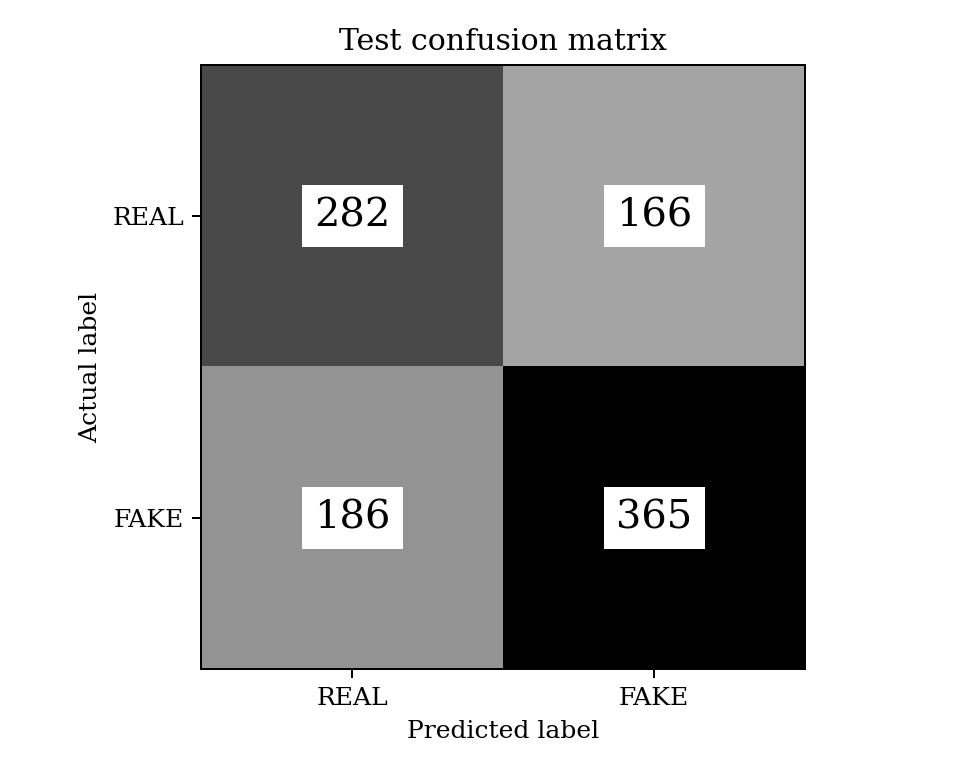

In [13]:
plt.rcParams.update({
    "font.family": "DejaVu Serif",
    "text.color": "black",
    "axes.labelcolor": "black"
})

fig, ax = plt.subplots(figsize=(5.3, 4.3))
ax.imshow(matrix, cmap="Greys", vmin=0)
ax.set(
    xticks=[0, 1],
    yticks=[0, 1],
    xticklabels=LABEL_NAMES,
    yticklabels=LABEL_NAMES,
    xlabel="Predicted label",
    ylabel="Actual label",
    title="Test confusion matrix"
)

for row in range(2):
    for column in range(2):
        ax.text(
            column, row, str(matrix[row, column]),
            ha="center", va="center", fontsize=16, color="black",
            bbox={"facecolor": "white", "edgecolor": "none", "pad": 5}
        )

fig.tight_layout()
fig.savefig(OUTPUT_FOLDER / "confusion_matrix.png", dpi=180)
plt.close(fig)
display(Image(filename=str(OUTPUT_FOLDER / "confusion_matrix.png")))

## Step 13 Compare the validation scores

A longer bar means a higher validation macro F1. The plot includes the majority
baseline so I can check whether the learned models do better than a simple rule.
These are **validation scores**, not the final test scores.

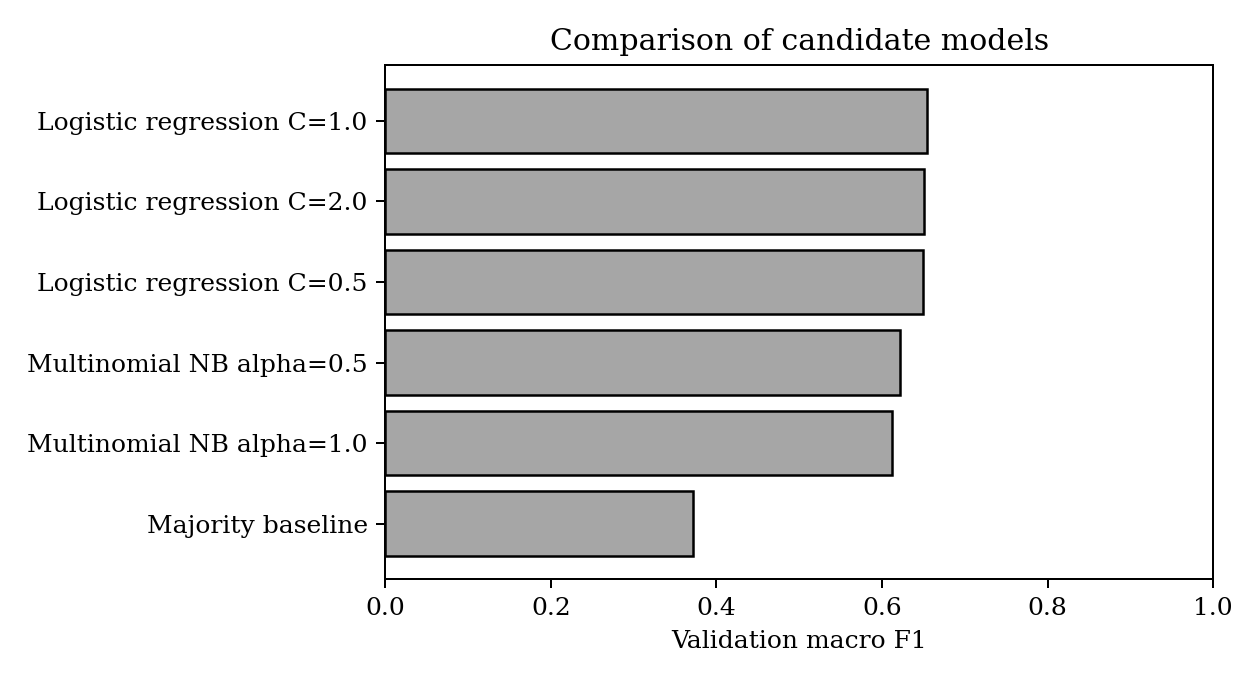

In [14]:
comparison = validation_results.iloc[::-1]

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(
    comparison["model"],
    comparison["validation_macro_f1"],
    color="0.65",
    edgecolor="black"
)
ax.set(
    xlim=(0, 1),
    xlabel="Validation macro F1",
    title="Comparison of candidate models"
)

fig.tight_layout()
fig.savefig(OUTPUT_FOLDER / "validation_comparison.png", dpi=180)
plt.close(fig)
display(Image(filename=str(OUTPUT_FOLDER / "validation_comparison.png")))

## Step 14 Show the ROC curve

The ROC curve shows how the FAKE class is detected at different score thresholds.
The dashed diagonal represents chance ranking. A higher AUC indicates better
ranking, but it does not mean that the scores are factual truth probabilities.

The curve is calculated with `roc_curve()` and drawn with Matplotlib. The same
predictions used for test evaluation are used here.

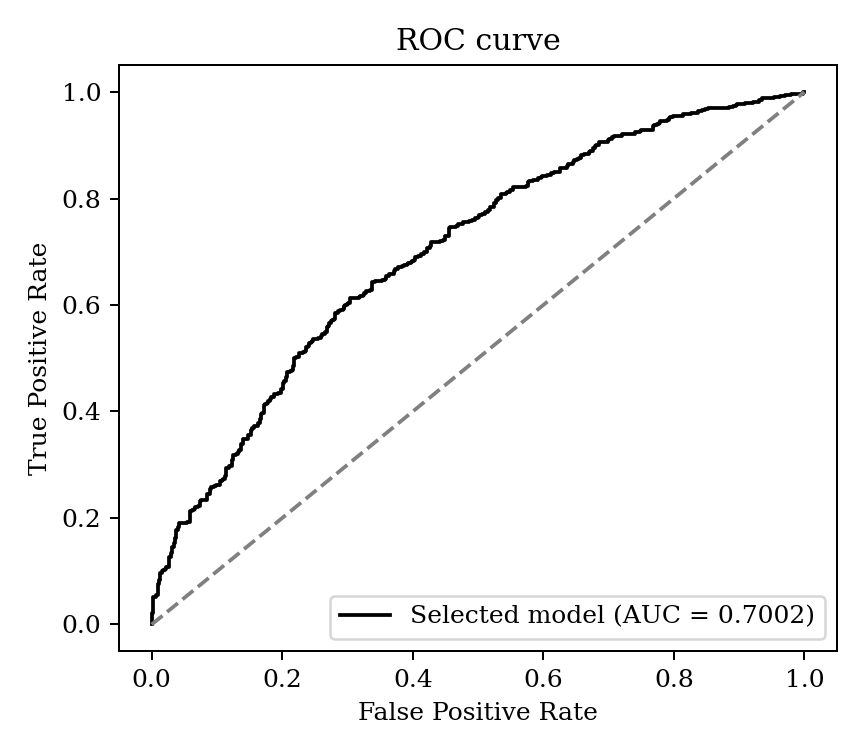

In [15]:
false_positive_rate, true_positive_rate, _ = roc_curve(
    actual_labels,
    fake_probabilities
)

fig, ax = plt.subplots(figsize=(4.8, 4.2))
ax.plot(
    false_positive_rate,
    true_positive_rate,
    color="black",
    label=f"Selected model (AUC = {roc_auc:.4f})"
)
ax.plot([0, 1], [0, 1], linestyle="--", color="0.5")
ax.set(
    xlabel="False Positive Rate",
    ylabel="True Positive Rate",
    title="ROC curve"
)
ax.legend(loc="lower right")

fig.tight_layout()
fig.savefig(OUTPUT_FOLDER / "roc_curve.png", dpi=180)
plt.close(fig)
display(Image(filename=str(OUTPUT_FOLDER / "roc_curve.png")))

## Step 15 Try an example

The function below cleans new text and sends it through the trained pipeline.
It does not train a new model.

- `predicted_label` is the class with the higher model score.
- `model_probability` is that class score; it is not a verified truth probability.
- `status` becomes **UNCERTAIN** if the score is below 0.60 or there is no known vocabulary.

The 0.60 threshold is a simple display rule. It was not used to exclude difficult
examples from the test scores. Blank text and inputs with fewer than three words
are rejected with a helpful message.

In [27]:
def predict_claim(model, text, threshold=0.60):
    """Predict a label and mark low model scores as uncertain."""
    if not isinstance(text, str) or not text.strip():
        raise ValueError("Enter a non-empty English statement.")

    if not 0.5 <= threshold <= 1.0:
        raise ValueError("Threshold must be between 0.5 and 1.0.")

    cleaned_text = clean_text(text)
    words = re.findall(r"\b\w+\b", cleaned_text)
    if len(words) < 3:
        raise ValueError("Enter at least three words.")

    features = model.named_steps["tfidf"].transform([cleaned_text])
    if features.nnz == 0:
        return {
            "predicted_label": None,
            "status": "UNCERTAIN",
            "model_probability": None,
            "explanation": "No recognized vocabulary. Verify using reliable sources."
        }

    probabilities = model.predict_proba([cleaned_text])[0]
    best_index = int(probabilities.argmax())
    class_number = int(model.classes_[best_index])
    predicted_label = LABEL_NAMES[class_number]
    probability = float(probabilities[best_index])

    if probability >= threshold:
        status = predicted_label
    else:
        status = "UNCERTAIN"

    return {
        "predicted_label": predicted_label,
        "status": status,
        "model_probability": round(probability, 4),
        "explanation": "This is a model prediction, not a verified fact-check."
    }


# Change this statement and rerun this cell to try your own input.
statement = "The government announced fund for public schools"
prediction = predict_claim(model, statement)

print("Statement:", statement)
print(json.dumps(prediction, indent=2))

statement = "Providence has the lowest crime rate in three decades."

prediction = predict_claim(model, statement)
print(json.dumps(prediction, indent=2))

Statement: The government announced fund for public schools
{
  "predicted_label": "FAKE",
  "status": "FAKE",
  "model_probability": 0.7578,
  "explanation": "This is a model prediction, not a verified fact-check."
}
{
  "predicted_label": "REAL",
  "status": "REAL",
  "model_probability": 0.8304,
  "explanation": "This is a model prediction, not a verified fact-check."
}


## Step 16 Save the results and the trained model

The pipeline contains both the learned TF-IDF converter and classifier. Saving
the complete pipeline means I can reuse them together for future predictions.

CSV files open as tables in Excel or a text editor. A JSON file stores named
values such as accuracy. A `.joblib` file stores the fitted Python model.
Only load model files from a trusted source; these files contain Python objects.

In [19]:
data_audit.to_csv(OUTPUT_FOLDER / "data_audit.csv", index=False)
validation_results.to_csv(OUTPUT_FOLDER / "validation_comparison.csv", index=False)

metrics_file = OUTPUT_FOLDER / "metrics.json"
metrics_file.write_text(json.dumps(metrics, indent=2), encoding="utf-8")

predictions = test[["id", "statement", "original_label", "label"]].copy()
predictions["predicted_label"] = predicted_labels
predictions["fake_model_probability"] = fake_probabilities
predictions.to_csv(OUTPUT_FOLDER / "test_predictions.csv", index=False)

incorrect_rows = predictions["label"] != predictions["predicted_label"]
errors = predictions[incorrect_rows]
errors.head(25).to_csv(OUTPUT_FOLDER / "error_examples.csv", index=False)

model_file = OUTPUT_FOLDER / "fake_news_model.joblib"
joblib.dump(model, model_file)
reloaded_model = joblib.load(model_file)

print("Saved the trained model and result tables in:", OUTPUT_FOLDER)

Saved the trained model and result tables in: results


In [22]:
summary = (
    f"I compared Naive Bayes and Logistic Regression using TF-IDF features. "
    f"The selected model was **{selected_model}**, chosen using validation macro F1. "
    f"On **{len(test):,} test statements**, it achieved **{accuracy:.2%} accuracy**, "
    f"**{macro_f1:.4f} macro F1**, and **{roc_auc:.4f} ROC AUC**. "
    f"All **{len(test_results)} functional checks passed**. "
    "The results show that word patterns give some useful information, but "
    "the model still makes mistakes and does not verify facts."
)

display(Markdown(summary))
print("\nNotebook run completed successfully.")

I compared Naive Bayes and Logistic Regression using TF-IDF features. The selected model was **Logistic regression C=1.0**, chosen using validation macro F1. On **999 test statements**, it achieved **64.76% accuracy**, **0.6452 macro F1**, and **0.7002 ROC AUC**. All **8 functional checks passed**. The results show that word patterns give some useful information, but the model still makes mistakes and does not verify facts.


Notebook run completed successfully.
